# KHÓA LUẬN TỐT NGHIỆP: PHÂN LOẠI RÁC THẢI ĐA CẤP VỚI HIERARCHICAL CONVNEXT-TINY & HỆ THỐNG AN TOÀN 2 CHỐT CHẶN (5-VIEW TTA)
---
### Cấu Trúc Pipeline Toàn Diện:
1. **Thiết lập cấu hình & Khám phá dữ liệu (80/10/10)**: Chia tập dữ liệu chuẩn xác (`SEED = 42`), ánh xạ phân cấp 4 lớp con (`glass`, `metal`, `paper`, `plastic`) vào 3 siêu lớp vật liệu (`cellulose`, `metal`, `polymer_glass`).
2. **Data Pipeline Quang Học (`ResizeMethod.AREA` $320 \times 320$)**: Tích hợp tăng cường hình học cùng `Mixup` và `CutMix` ($\alpha = 0.2$).
3. **Kiến Trúc Hierarchical ConvNeXt-Tiny**: Kết hợp `CosineDense(scale=20.0)` cho nhánh phân loại chính (trọng số $0.70$) và nhánh giám sát siêu lớp vật liệu (trọng số $0.30$).
4. **Huấn Luyện 2 Giai Đoạn**: Stage 1 Warm-up Heads (15 epochs) và Stage 2 Deep Fine-Tuning 40 layers đỉnh (25 epochs với CosineDecay).
5. **Suy Luận 5-View TTA & Tìm Ngưỡng An Toàn Thống Kê ($\mu - \sigma$)**: Khóa 2 chốt chặn cốt lõi từ tập Validation:
   - **Kỹ thuật 1 (Confidence Gate)**: Độ tự tin $\tau_{\text{conf}} = \mu_{\text{conf}} - \sigma_{\text{conf}}$
   - **Kỹ thuật 2 (Margin Gate)**: Khoảng cách biên Top1 - Top2 $\tau_{\text{margin}} = \mu_{\text{margin}} - \sigma_{\text{margin}}$
6. **Kiểm Thử Trên Tập Test, Báo Cáo Nghiệm Thu & Trực Quan Hóa**: Báo cáo số mẫu tự động gắp, chuyển khay thủ công, lỗi chặn được, lỗi lọt lưới và hiển thị hình ảnh chi tiết.

In [1]:
# CELL 1 === 1. KHỞI TẠO THƯ VIỆN & THIẾT LẬP CẤU HÌNH ===
import os
import gc
import sys
import glob
import time
import json
import random
from collections import defaultdict, Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.special import softmax

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as preprocess_convnext

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Cấu hình GPU động
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f'✅ Đã phát hiện và kích hoạt {len(gpus)} GPU: {[g.name for g in gpus]}')
    except RuntimeError as e:
        print(f'⚠️ Cảnh báo GPU: {e}')
else:
    print('⚠️ Không tìm thấy GPU, hệ thống sẽ chạy trên CPU.')

# Thiết lập Seed cố định đảm bảo tính tái lập
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Siêu tham số chuẩn từ mytrashnet-convnext-retrain-tta-safety
IMG_SIZE = (320, 320)
BATCH_SIZE = 32
EPOCHS_STAGE1 = 15
EPOCHS_STAGE2 = 25
MIXUP_ALPHA = 0.2

STAGE1_CHECKPOINT = 'best_trashnet_convnext_stage1.keras'
STAGE2_CHECKPOINT = 'best_trashnet_convnext_retrained.keras'

print('✅ Đã thiết lập xong môi trường và siêu tham số cho Hierarchical ConvNeXt-Tiny!')

✅ Đã phát hiện và kích hoạt 2 GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']
✅ Đã thiết lập xong môi trường và siêu tham số cho Hierarchical ConvNeXt-Tiny!


In [2]:
# CELL 2 === 2. KHÁM PHÁ DATASET, ÁNH XẠ SIÊU LỚP & PHÂN CHIA TẬP DỮ LIỆU (80/10/10) ===
def discover_dataset():
    priority_candidates = [
        '/kaggle/input/datasets/vminhkhoi/dataset-trashnet-2/MyTrashNet4Class',
        '/kaggle/input/dataset-trashnet-2/MyTrashNet4Class',
        '/kaggle/input/dataset-trashnet-2/MyTrashNet',
        '/kaggle/input/dataset-trashnet-2',
        '/kaggle/input/trashnet-dataset-v5-cleaner/MyTrashNet',
        '/kaggle/input/mytrashnet',
        '/kaggle/input/trashnet/dataset-resized',
        '/content/drive/MyDrive/KLTN/MyTrashNet4Class',
        './MyTrashNet4Class',
        '../MyTrashNet4Class'
    ]
    for p in priority_candidates:
        if os.path.exists(p) and os.path.isdir(p):
            subdirs = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d)) and not d.startswith('.')]
            has_images = any(
                len([f for f in os.listdir(os.path.join(p, d)) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))]) > 0
                for d in subdirs
            )
            if has_images and len(subdirs) >= 3:
                return p

    for root in ['/kaggle/input', '/content', '.']:
        if os.path.exists(root):
            for dirpath, dirnames, filenames in os.walk(root):
                valid_sub = [d for d in dirnames if not d.startswith('.')]
                if len(valid_sub) >= 3:
                    sub_with_imgs = 0
                    for d in valid_sub:
                        p_sub = os.path.join(dirpath, d)
                        if any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in os.listdir(p_sub)[:10]):
                            sub_with_imgs += 1
                    if sub_with_imgs >= 3:
                        return dirpath
    return None

dataset_path = discover_dataset()
if dataset_path is None:
    raise FileNotFoundError('❌ Không thể tìm thấy thư mục dataset chứa ảnh!')

print(f'📁 Thư mục Dataset được phát hiện: {dataset_path}')

TARGET_CLASSES = ['glass', 'metal', 'paper', 'plastic']
class_dirs = [d for d in sorted(os.listdir(dataset_path))
              if os.path.isdir(os.path.join(dataset_path, d)) and not d.startswith('.')]

if any(d.lower() in TARGET_CLASSES for d in class_dirs):
    active_dirs = [d for d in class_dirs if d.lower() in TARGET_CLASSES]
else:
    active_dirs = class_dirs

records = []
for c in active_dirs:
    c_path = os.path.join(dataset_path, c)
    files = sorted([f for f in os.listdir(c_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))])
    for f in files:
        records.append({
            'filepath': os.path.join(c_path, f),
            'filename': f,
            'label': c
        })

df_dataset = pd.DataFrame(records)
print(f'📊 Tổng số ảnh quét được trong tập dữ liệu: {len(df_dataset):,} ảnh')

sub_labels = sorted(df_dataset['label'].unique().tolist())
num_sub_classes = len(sub_labels)
print(f'✅ Phát hiện {num_sub_classes} lớp rác thực tế: {sub_labels}')
for c in sub_labels:
    cnt = len(df_dataset[df_dataset['label'] == c])
    print(f' - Lớp {c:12s}: {cnt:5d} ảnh ({cnt/len(df_dataset)*100:.2f}%)')

class_labels = sub_labels
sub_to_idx = {label: i for i, label in enumerate(sub_labels)}
idx_to_sub = {i: label for i, label in enumerate(sub_labels)}

SUPER_MAP = {
    'cardboard': 'cellulose',
    'paper':     'cellulose',
    'glass':     'polymer_glass',
    'plastic':   'polymer_glass',
    'metal':     'metal'
}

sub_to_super_name = {c: SUPER_MAP.get(c, c) for c in sub_labels}
super_labels = sorted(list(set(sub_to_super_name.values())))
num_super_classes = len(super_labels)
super_to_idx = {name: i for i, name in enumerate(super_labels)}
idx_to_super = {i: name for i, name in enumerate(super_labels)}

SUB_TO_SUPER = {sub_to_idx[c]: super_to_idx[sub_to_super_name[c]] for c in sub_labels}

print(f'\n✅ Cấu hình phân cấp Siêu lớp ({num_super_classes} siêu nhóm):')
for c in sub_labels:
    s_name = sub_to_super_name[c]
    print(f'   [{c:10s}] -> Siêu nhóm: {s_name} (ID: {super_to_idx[s_name]})')

# Chia tập dữ liệu 80% Train - 10% Validation - 10% Test
train_df, temp_df = train_test_split(df_dataset, test_size=0.20, random_state=SEED, stratify=df_dataset['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label'])

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f'\n📊 Phân chia dữ liệu phân tầng chuẩn (80/10/10):')
print(f' - Train      : {len(train_df):,} ảnh ({len(train_df)/len(df_dataset)*100:.1f}%)')
print(f' - Validation : {len(val_df):,} ảnh ({len(val_df)/len(df_dataset)*100:.1f}%)')
print(f' - Test       : {len(test_df):,} ảnh ({len(test_df)/len(df_dataset)*100:.1f}%)')
def extract_ground_truth_label(filename, fallback_label=None):
    """
    Trích xuất nhãn thực tế chuẩn (Ground Truth) từ tên file ảnh.
    Đảm bảo việc đánh giá trên tập Test luôn dựa trên nhãn gốc của file ảnh,
    không bị phụ thuộc vào tên thư mục chứa ảnh (tránh sai lệch khi ảnh bị gán nhãn sai).
    """
    fn = os.path.basename(str(filename)).lower()
    for c in TARGET_CLASSES:
        if fn.startswith(c) or f'_{c}' in fn or f'{c}_' in fn:
            return c
    for c in TARGET_CLASSES:
        if c in fn:
            return c
    if 'cardboard' in fn:
        return 'paper'
    return fallback_label if fallback_label else 'unlabeled'

# Đảm bảo nhãn của tập Test được trích xuất trực tiếp từ tên file (Ground Truth chuẩn)
test_df['label_folder'] = test_df['label']
test_df['label'] = test_df.apply(lambda r: extract_ground_truth_label(r['filename'], r['label']), axis=1)

# Kiểm tra xem có ảnh nào trong tập test bị lệch nhãn giữa tên thư mục và tên file không
mismatches = test_df[test_df['label'] != test_df['label_folder']]
if len(mismatches) > 0:
    print(f'⚠️ Cảnh báo: Phát hiện {len(mismatches)} ảnh trong tập Test có tên thư mục khác với tên file. Đã đồng bộ sang nhãn tên file!')
else:
    print('✅ Tất cả nhãn thư mục và nhãn tên file trong tập Test khớp nhau 100%.')

# Lưu lại tập Test chuẩn 10% (Gold Standard Benchmark) để Stage 2 đối chiếu
test_benchmark_path = 'test_set_chuan_10_percent.csv'
test_df[['filename', 'filepath', 'label']].to_csv(test_benchmark_path, index=False, encoding='utf-8-sig')
print(f"💾 Đã xuất tập Test chuẩn 10% ra file '{test_benchmark_path}' ({len(test_df)} mẫu) để làm bộ quy chuẩn đánh giá đối sánh V1 và V2.")

📁 Thư mục Dataset được phát hiện: /kaggle/input/datasets/vminhkhoi/dataset-trashnet-2/MyTrashNet4Class
📊 Tổng số ảnh quét được trong tập dữ liệu: 8,061 ảnh
✅ Phát hiện 4 lớp rác thực tế: ['glass', 'metal', 'paper', 'plastic']
 - Lớp glass       :  2012 ảnh (24.96%)
 - Lớp metal       :  2016 ảnh (25.01%)
 - Lớp paper       :  2016 ảnh (25.01%)
 - Lớp plastic     :  2017 ảnh (25.02%)

✅ Cấu hình phân cấp Siêu lớp (3 siêu nhóm):
   [glass     ] -> Siêu nhóm: polymer_glass (ID: 2)
   [metal     ] -> Siêu nhóm: metal (ID: 1)
   [paper     ] -> Siêu nhóm: cellulose (ID: 0)
   [plastic   ] -> Siêu nhóm: polymer_glass (ID: 2)

📊 Phân chia dữ liệu phân tầng chuẩn (80/10/10):
 - Train      : 6,448 ảnh (80.0%)
 - Validation : 806 ảnh (10.0%)
 - Test       : 807 ảnh (10.0%)
✅ Tất cả nhãn thư mục và nhãn tên file trong tập Test khớp nhau 100%.
💾 Đã xuất tập Test chuẩn 10% ra file 'test_set_chuan_10_percent.csv' (807 mẫu) để làm bộ quy chuẩn đánh giá đối sánh V1 và V2.


In [3]:
# CELL 3 === 3. THIẾT LẬP DATA PIPELINE AREA RESAMPLING (320x320) & MIXUP/CUTMIX ===
geometric_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    layers.RandomRotation(factor=(-0.25, 0.25), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomContrast(factor=0.2, seed=SEED),
], name='geometric_augmentation')

def sample_beta(alpha, shape=()):
    gamma1 = tf.random.gamma(shape, alpha, 1.0)
    gamma2 = tf.random.gamma(shape, alpha, 1.0)
    return gamma1 / (gamma1 + gamma2)

def apply_mixup(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    lam = sample_beta(alpha)
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    mixed_img = lam * images + (1.0 - lam) * img_shuffled
    mixed_sub = lam * sub_labels + (1.0 - lam) * sub_shuffled
    mixed_sup = lam * super_labels + (1.0 - lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def apply_cutmix(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    lam = sample_beta(alpha)
    cut_ratio = tf.sqrt(1.0 - lam)
    img_h = tf.cast(tf.shape(images)[1], tf.float32)
    img_w = tf.cast(tf.shape(images)[2], tf.float32)
    cut_h = tf.cast(img_h * cut_ratio, tf.int32)
    cut_w = tf.cast(img_w * cut_ratio, tf.int32)
    cx = tf.random.uniform([], 0, tf.shape(images)[2], dtype=tf.int32)
    cy = tf.random.uniform([], 0, tf.shape(images)[1], dtype=tf.int32)
    ymin = tf.clip_by_value(cy - cut_h // 2, 0, tf.shape(images)[1])
    xmin = tf.clip_by_value(cx - cut_w // 2, 0, tf.shape(images)[2])
    ymax = tf.clip_by_value(cy + cut_h // 2, 0, tf.shape(images)[1])
    xmax = tf.clip_by_value(cx + cut_w // 2, 0, tf.shape(images)[2])
    mask = tf.pad(
        tf.ones([ymax - ymin, xmax - xmin, tf.shape(images)[3]], dtype=tf.float32),
        [[ymin, tf.shape(images)[1] - ymax], [xmin, tf.shape(images)[2] - xmax], [0, 0]]
    )
    mask = tf.expand_dims(mask, 0)
    mixed_img = images * (1.0 - mask) + img_shuffled * mask
    actual_lam = 1.0 - tf.cast((ymax - ymin) * (xmax - xmin), tf.float32) / (img_h * img_w)
    mixed_sub = actual_lam * sub_labels + (1.0 - actual_lam) * sub_shuffled
    mixed_sup = actual_lam * super_labels + (1.0 - actual_lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def batch_mixup_cutmix(images, labels):
    images = tf.cast(images, tf.float32)
    sub_l = tf.cast(labels['sub_class'], tf.float32)
    sup_l = tf.cast(labels['super_class'], tf.float32)
    coin = tf.random.uniform([])
    m_img, m_sub, m_sup = tf.cond(
        coin < 0.5,
        lambda: apply_mixup(images, sub_l, sup_l, alpha=MIXUP_ALPHA),
        lambda: apply_cutmix(images, sub_l, sup_l, alpha=MIXUP_ALPHA)
    )
    return m_img, {'sub_class': m_sub, 'super_class': m_sup}

def create_area_dataset(dataframe, is_training=False, batch_size=32):
    filepaths = dataframe['filepath'].values
    sub_indices = dataframe['label'].map(sub_to_idx).values
    super_indices = np.array([SUB_TO_SUPER[idx] for idx in sub_indices])

    sub_onehot = tf.keras.utils.to_categorical(sub_indices, num_classes=num_sub_classes).astype(np.float32)
    super_onehot = tf.keras.utils.to_categorical(super_indices, num_classes=num_super_classes).astype(np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((
        filepaths,
        {'sub_class': sub_onehot, 'super_class': super_onehot}
    ))

    if is_training:
        dataset = dataset.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    def parse_img(filename, labels):
        img_bytes = tf.io.read_file(filename)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)
        return img, labels

    dataset = dataset.map(parse_img, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)

    if is_training:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(geometric_augmentation(x, training=True)), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        dataset = dataset.map(batch_mixup_cutmix, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(x), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    dataset.filepaths = list(filepaths)
    dataset.classes = list(sub_indices)
    dataset.super_classes = list(super_indices)
    return dataset

train_generator = create_area_dataset(train_df, is_training=True, batch_size=BATCH_SIZE)
val_generator = create_area_dataset(val_df, is_training=False, batch_size=BATCH_SIZE)
test_generator = create_area_dataset(test_df, is_training=False, batch_size=BATCH_SIZE)

print(f'✅ Đã khởi tạo xong Data Pipeline Area Resampling ({IMG_SIZE[0]}x{IMG_SIZE[1]}) cho ConvNeXt!')

✅ Đã khởi tạo xong Data Pipeline Area Resampling (320x320) cho ConvNeXt!


In [4]:
# CELL 4 === 4. XÂY DỰNG KIẾN TRÚC MẠNG ĐA TÁC VỤ PHÂN CẤP HIERARCHICAL CONVNEXT-TINY ===
try:
    register_serializable = tf.keras.utils.register_keras_serializable
except AttributeError:
    import keras
    register_serializable = keras.saving.register_keras_serializable

@register_serializable(package='CustomLayers', name='CosineDense')
class CosineDense(layers.Layer):
    def __init__(self, units, scale=20.0, **kwargs):
        super(CosineDense, self).__init__(**kwargs)
        self.units = units
        self.scale = scale

    def build(self, input_shape):
        self.kernel = self.add_weight(
            name='kernel',
            shape=(input_shape[-1], self.units),
            initializer='glorot_uniform',
            trainable=True
        )

    def call(self, inputs):
        norm_inputs = tf.nn.l2_normalize(inputs, axis=-1)
        norm_kernel = tf.nn.l2_normalize(self.kernel, axis=0)
        cosine_sim = tf.matmul(norm_inputs, norm_kernel)
        return self.scale * cosine_sim

    def get_config(self):
        config = super(CosineDense, self).get_config()
        config.update({'units': self.units, 'scale': self.scale})
        return config

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name='input_image')
base_model = ConvNeXtTiny(include_top=False, weights='imagenet', input_tensor=inputs)
base_model.trainable = False

x = base_model.output
gap = layers.GlobalAveragePooling2D(name='gap')(x)
gmp = layers.GlobalMaxPooling2D(name='gmp')(x)
shared_features = layers.concatenate([gap, gmp], name='concat_pooling')

shared_features = layers.Dense(1024, activation=None, name='shared_dense')(shared_features)
shared_features = layers.LayerNormalization(name='shared_ln')(shared_features)
shared_features = layers.Activation('gelu', name='shared_gelu')(shared_features)
shared_features = layers.Dropout(0.3, name='shared_dropout')(shared_features)

norm_features = layers.Lambda(lambda t: tf.nn.l2_normalize(t, axis=-1), output_shape=(1024,), name='norm_features')(shared_features)

sub_logits = CosineDense(num_sub_classes, scale=20.0, name='cosine_logits')(norm_features)
sub_class_output = layers.Activation('softmax', name='sub_class', dtype='float32')(sub_logits)

super_dense = layers.Dense(256, activation='gelu', name='super_dense')(shared_features)
super_dense = layers.Dropout(0.2, name='super_dropout')(super_dense)
super_class_output = layers.Dense(num_super_classes, activation='softmax', name='super_class', dtype='float32')(super_dense)

model = Model(
    inputs=inputs,
    outputs={'sub_class': sub_class_output, 'super_class': super_class_output},
    name='Hierarchical_ConvNeXtTiny_NewLabels'
)

losses = {
    'sub_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    'super_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05)
}
loss_weights = {
    'sub_class': 0.70,
    'super_class': 0.30
}
metrics = {
    'sub_class': ['accuracy'],
    'super_class': ['accuracy']
}

optimizer_stage1 = tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4)
model.compile(
    optimizer=optimizer_stage1,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

print('=' * 80)
print('✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:')
print(f' - Tổng số tham số : {model.count_params():,}')
print('=' * 80)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:
 - Tổng số tham số : 29,663,331


In [ ]:
# CELL 5 === 5. GIAI ĐOẠN 1: HUẤN LUYỆN WARM-UP HEADS (15 EPOCHS) ===
callbacks_stage1 = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_sub_class_loss', mode='min', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=6, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE1_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 1] Huấn luyện Warm-up Heads ConvNeXt-Tiny ({EPOCHS_STAGE1} epochs)...')
print('=' * 80)
t_st1 = time.time()
history_stage1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)
print(f'✅ Hoàn tất Giai đoạn 1 trong {round(time.time() - t_st1, 1)}s!')

In [ ]:
# CELL 6 === 6. GIAI ĐOẠN 2: DEEP FINE-TUNING 40 LAYERS ĐỈNH VỚI COSINE DECAY (25 EPOCHS) ===
base_model.trainable = True

unfreeze_layers = 40
for layer in base_model.layers[:-unfreeze_layers]:
    layer.trainable = False
for layer in base_model.layers[-unfreeze_layers:]:
    layer.trainable = True

unfrozen_cnt = sum(1 for l in base_model.layers if l.trainable)
print(f'🔓 ConvNeXt Fine-Tuning: Đã mở khóa {unfrozen_cnt} layers đỉnh cao nhất!')

total_steps = len(train_df) // BATCH_SIZE * EPOCHS_STAGE2
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=0.01
)

optimizer_stage2 = tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4)

model.compile(
    optimizer=optimizer_stage2,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE2_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 2] Deep Fine-Tuning ConvNeXt-Tiny ({EPOCHS_STAGE2} epochs)...')
print('=' * 80)
t_st2 = time.time()
history_stage2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)
print(f'✅ Hoàn tất Giai đoạn 2 trong {round(time.time() - t_st2, 1)}s!')

In [ ]:
# CELL 7 === 7. LƯU LỊCH SỬ HUẤN LUYỆN & TRỰC QUAN HÓA ĐỒ THỊ QUÁ TRÌNH HỌC ===
def clean_history(hist):
    return {k: [float(val) for val in v] for k, v in hist.items()}

history_dict = {
    'stage1': clean_history(history_stage1.history),
    'stage2': clean_history(history_stage2.history)
}

with open('training_history_convnext.json', 'w', encoding='utf-8') as f:
    json.dump(history_dict, f, indent=4)
print('✅ Đã lưu lịch sử huấn luyện vào file training_history_convnext.json')

# Vẽ đồ thị tiến trình huấn luyện 2 giai đoạn
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

acc_all = history_dict['stage1']['sub_class_accuracy'] + history_dict['stage2']['sub_class_accuracy']
val_acc_all = history_dict['stage1']['val_sub_class_accuracy'] + history_dict['stage2']['val_sub_class_accuracy']
loss_all = history_dict['stage1']['sub_class_loss'] + history_dict['stage2']['sub_class_loss']
val_loss_all = history_dict['stage1']['val_sub_class_loss'] + history_dict['stage2']['val_sub_class_loss']
split_epoch = len(history_dict['stage1']['sub_class_accuracy']) - 1

axes[0].plot(acc_all, label='Train Sub-class Accuracy', color='tab:blue', lw=2)
axes[0].plot(val_acc_all, label='Val Sub-class Accuracy', color='tab:orange', lw=2)
axes[0].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[0].set_title('Đồ thị Sub-class Accuracy qua các Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(loss_all, label='Train Sub-class Loss', color='tab:blue', lw=2)
axes[1].plot(val_loss_all, label='Val Sub-class Loss', color='tab:orange', lw=2)
axes[1].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[1].set_title('Đồ thị Sub-class Loss qua các Epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('convnext_training_curves.png', dpi=300)
plt.show()

In [5]:
# CELL 8 === 8. SUY LUẬN 5-VIEW TTA & TỰ ĐỘNG TÌM BỘ NGƯỠNG AN TOÀN RIÊNG CHO TỪNG LỚP ===

# ==============================================================================
# BƯỚC 0: TRUYỀN ĐƯỜNG DẪN & NẠP MODEL KHI MỞ LẠI MÁY
# ==============================================================================
MODEL_PATH = '/kaggle/input/models/vminhkhoi/convnext-tiny/keras/default/1/best_trashnet_convnext_retrained.keras'

# Dự phòng nếu chạy trên máy cá nhân
if not os.path.exists(MODEL_PATH):
    local_candidates = [
        'best_trashnet_convnext_retrained.keras',
        './best_trashnet_convnext_retrained.keras',
        'ConvNeXtTiny/best_trashnet_convnext_retrained.keras'
    ]
    for cand in local_candidates:
        if os.path.exists(cand):
            MODEL_PATH = cand
            break

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"❌ Không tìm thấy file model tại: '{MODEL_PATH}'. Vui lòng kiểm tra lại đường dẫn!")

print(f"📦 Đang nạp mô hình từ: '{MODEL_PATH}' ({os.path.getsize(MODEL_PATH) / (1024*1024):.2f} MB)...")

try:
    custom_objects = {'CosineDense': CosineDense}
    model = tf.keras.models.load_model(MODEL_PATH, custom_objects=custom_objects, safe_mode=False, compile=False)
    for l in model.layers:
        if hasattr(l, 'function') and hasattr(l.function, '__globals__'):
            l.function.__globals__['tf'] = tf
            l.function.__globals__['tensorflow'] = tf
    print(f"✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny ({model.count_params():,} tham số)!")
except Exception as e:
    print(f"ℹ️ Thử nạp theo dạng weights: {e}")
    model.load_weights(MODEL_PATH)
    print("✅ Đã nạp thành công trọng số vào kiến trúc mô hình!")

sub_logits_model = Model(inputs=model.input, outputs=model.get_layer('cosine_logits').output)

def make_tta_dataset(filepaths, view_idx=0, batch_size=64):
    ds = tf.data.Dataset.from_tensor_slices(filepaths)
    def load_and_aug(fpath):
        img_bytes = tf.io.read_file(fpath)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)

        h, w = IMG_SIZE
        if view_idx == 0: pass
        elif view_idx == 1: img = tf.image.flip_left_right(img)
        elif view_idx == 2: img = tf.image.rot90(img, k=1)
        elif view_idx == 3: img = tf.image.rot90(img, k=3)
        elif view_idx == 4:
            crop_size = int(h * 0.90)
            offset = (h - crop_size) // 2
            img_c = tf.image.crop_to_bounding_box(img, offset, offset, crop_size, crop_size)
            img = tf.image.resize(img_c, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)

        return preprocess_convnext(img)

    ds = ds.map(load_and_aug, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

print('=' * 105)
print('BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...')
print('=' * 105)
val_filepaths = val_df['filepath'].values
val_trues = val_df['label'].map(sub_to_idx).values
N_VAL = len(val_filepaths)

val_views_probs = []
for v in range(5):
    print(f' -> Đang dự đoán View {v+1}/5 trên tập Validation...')
    v_ds = make_tta_dataset(val_filepaths, view_idx=v, batch_size=BATCH_SIZE*2)
    logits = sub_logits_model.predict(v_ds, batch_size=BATCH_SIZE*2, verbose=0)
    probs = softmax(logits, axis=1)
    val_views_probs.append(probs)

val_tta_probs = np.mean(val_views_probs, axis=0)
val_tta_preds = np.argmax(val_tta_probs, axis=1)

val_sorted_probs = np.sort(val_tta_probs, axis=1)
val_max_confs = val_sorted_probs[:, -1]
val_margins = val_sorted_probs[:, -1] - val_sorted_probs[:, -2]

val_acc = np.mean(val_tta_preds == val_trues) * 100.0
val_errors = int(np.sum(val_tta_preds != val_trues))
print(f'\n✅ Validation 5-View TTA Accuracy: {val_acc:.2f}% ({val_errors} lỗi trên {N_VAL} mẫu)')
print('\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---')
print(classification_report(val_trues, val_tta_preds, target_names=class_labels, digits=4))

# ==============================================================================
# BƯỚC 2: KHẢO SÁT & TỐI ƯU HÓA NGƯỠNG CHỐT 1 RIÊNG BIỆT CHO TỪNG LỚP (PER-CLASS)
# ==============================================================================
K1_CANDIDATES = [0.8, 1.0, 1.2, 1.4, 1.5, 1.6, 1.8, 2.0]

TAU_CONF_DICT = {}   # Lưu ngưỡng riêng của từng lớp: {class_idx: tau}
BEST_K1_DICT = {}    # Lưu hệ số k1 tốt nhất của từng lớp

print('\n' + '=' * 105)
print('📊 [BẢNG 1] KHẢO SÁT CHỐT 1 (CONFIDENCE GATE) RIÊNG TỪNG LỚP:')
print('=' * 105)

for c_idx, c_name in enumerate(class_labels):
    # Lọc các mẫu dự đoán đúng của riêng lớp c_name để tính mean và std đặc trưng
    mask_correct_c = (val_tta_preds == c_idx) & (val_tta_preds == val_trues)
    confs_c = val_max_confs[mask_correct_c]
    mu_c = float(np.mean(confs_c))
    sigma_c = float(np.std(confs_c))
    
    # Tất cả các mẫu mô hình dự đoán là lớp c_name
    mask_pred_c = (val_tta_preds == c_idx)
    total_pred_c = int(np.sum(mask_pred_c))
    
    print(f"\n🏷️ LỚP [{c_name.upper()}]: (mu = {mu_c*100:.2f}%, sigma = {sigma_c*100:.2f}%, Tổng dự đoán: {total_pred_c} mẫu)")
    print(f"{'Hệ số k1':>10} {'Ngưỡng Conf':>14} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp lớp':>22}  {'Đánh giá'}")
    print('-' * 100)
    
    class_results = []
    for k in K1_CANDIDATES:
        tau = float(np.clip(mu_c - k * sigma_c, 0.50, 0.99))
        
        # Mẫu dự đoán là c_name và vượt qua ngưỡng tau
        pass_gate = mask_pred_c & (val_max_confs >= tau)
        leaked_errors = int(np.sum(pass_gate & (val_trues != c_idx)))
        picked_samples = int(np.sum(pass_gate))
        pick_rate = (picked_samples / total_pred_c * 100.0) if total_pred_c > 0 else 0.0
        
        class_results.append({
            'k': k,
            'tau': tau,
            'leaked': leaked_errors,
            'picked': picked_samples,
            'total': total_pred_c,
            'rate': pick_rate
        })
        
    # Tiêu chí chọn k tối ưu cho lớp c_name:
    # 1. Số lỗi lọt lưới nhỏ nhất (ưu tiên 0 lỗi)
    # 2. Tỷ lệ gắp cao nhất
    # 3. Nếu hòa thì chọn ngưỡng tau cao nhất (an toàn nhất)
    min_err = min(r['leaked'] for r in class_results)
    valid_candidates = [r for r in class_results if r['leaked'] == min_err]
    max_rate = max(r['rate'] for r in valid_candidates)
    best_candidate = max([r for r in valid_candidates if r['rate'] == max_rate], key=lambda x: x['tau'])
    
    for r in class_results:
        k = r['k']
        tau = r['tau']
        leaked = r['leaked']
        picked = r['picked']
        total = r['total']
        rate = r['rate']
        
        if k == best_candidate['k']:
            status = "⭐ ĐIỂM TỐI ƯU (0 lỗi & gắp tối đa)" if leaked == 0 else "⭐ ĐIỂM TỐI ƯU (Lỗi tối thiểu)"
        elif leaked == 0:
            status = "✅ An toàn (Bắt nhầm mẫu đúng)"
        else:
            status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
            
        print(f"k1 = {k:<5.1f}   >= {tau*100:>6.2f}%   {leaked:>10d} lỗi   {rate:>6.2f}% ({picked:>3d}/{total:<3d})   {status}")
        
    TAU_CONF_DICT[c_idx] = best_candidate['tau']
    BEST_K1_DICT[c_idx] = best_candidate['k']

# Tổng hợp bộ 4 ngưỡng Chốt 1 đã chốt
print('\n' + '=' * 105)
print('🎯 TỔNG HỢP BỘ 4 NGƯỠNG TỰ TIN (CHỐT 1) THÍCH ỨNG THEO TỪNG LỚP:')
print('=' * 105)
for c_idx, c_name in enumerate(class_labels):
    print(f" * Lớp {c_name:<10s}: k1 = {BEST_K1_DICT[c_idx]:.1f}  -->  Ngưỡng Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}%")

# Tính kết quả Chốt 1 trên toàn bộ tập Validation
val_sample_tau_conf = np.array([TAU_CONF_DICT[p] for p in val_tta_preds])
val_pass_1 = (val_max_confs >= val_sample_tau_conf)
val_p1_cov = np.mean(val_pass_1) * 100.0
val_p1_err = int(np.sum(val_pass_1 & (val_tta_preds != val_trues)))
print('-' * 105)
print(f"👉 Hiệu quả tổng hợp Chốt 1: Tự động gắp {val_p1_cov:.2f}% ({np.sum(val_pass_1)}/{N_VAL} mẫu) | Số lỗi lọt lưới: {val_p1_err} lỗi")

# ==============================================================================
# BƯỚC 3: CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP CHỐT 2 (MARGIN GATE)
# ==============================================================================
mean_margin, std_margin = float(np.mean(val_margins[val_tta_preds == val_trues])), float(np.std(val_margins[val_tta_preds == val_trues]))
K2_CANDIDATES = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.2, 2.4, 2.6]

print('\n' + '=' * 105)
print(f"📊 [BẢNG 2] CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP VỚI CHỐT 2 (MARGIN GATE):")
print(f"   (Thống kê Margin: mu = {mean_margin*100:.2f}%, sigma = {std_margin*100:.2f}%)")
print('=' * 105)
print(f"{'Thử Chốt 2':>15} {'Ngưỡng Margin':>16} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp kết hợp':>22}  {'Đánh giá khi phối hợp'}")
print('-' * 105)

results_table_2 = []
for k2 in K2_CANDIDATES:
    tau_m = float(np.clip(mean_margin - k2 * std_margin, 0.30, 0.95))
    pass_2 = (val_margins >= tau_m)
    pass_combined = val_pass_1 & pass_2
    
    leaked_combined = int(np.sum(pass_combined & (val_tta_preds != val_trues)))
    picked_combined = int(np.sum(pass_combined))
    cov_combined = (picked_combined / N_VAL) * 100.0
    
    results_table_2.append({
        'k2': k2,
        'tau_m': tau_m,
        'leaked': leaked_combined,
        'picked': picked_combined,
        'cov': cov_combined
    })

# Tiêu chí chọn k2 tối ưu: 0 lỗi, tỷ lệ gắp cao nhất, và ngưỡng tau_m cao nhất (an toàn nhất)
min_err_t2 = min(r['leaked'] for r in results_table_2)
valid_t2 = [r for r in results_table_2 if r['leaked'] == min_err_t2]
max_cov_t2 = max(r['cov'] for r in valid_t2)
best_t2 = max([r for r in valid_t2 if r['cov'] == max_cov_t2], key=lambda x: x['tau_m'])

for r in results_table_2:
    k2 = r['k2']
    tau_m = r['tau_m']
    leaked = r['leaked']
    picked = r['picked']
    cov = r['cov']
    
    if k2 == best_t2['k2']:
        status = "⭐ ĐIỂM TỐI ƯU (Tự động chọn: An toàn cao nhất & gắp tối đa)"
    elif leaked == 0 and cov < max_cov_t2:
        status = "✅ An toàn (Bắt nhầm nhiều mẫu đúng)"
    elif leaked == 0 and cov == max_cov_t2:
        status = f"✅ An toàn phối hợp (Gắp tối đa {cov:.2f}%)"
    else:
        status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
        
    print(f"k2 = {k2:<5.1f}   >= {tau_m*100:>6.2f}%   {leaked:>10d} lỗi   {cov:>6.2f}% ({picked:>3d}/{N_VAL:<3d})   {status}")

# Khóa 2 chốt an toàn chính thức vào biến môi trường
TAU_MARGIN = best_t2['tau_m']
BEST_K2 = best_t2['k2']

# Kiểm tra tổng thể hệ thống 2 Chốt
val_pass_2 = (val_margins >= TAU_MARGIN)
val_is_auto = val_pass_1 & val_pass_2
val_is_error = (val_tta_preds != val_trues)

val_auto_cov = np.mean(val_is_auto) * 100.0
val_auto_acc = np.mean(val_tta_preds[val_is_auto] == val_trues[val_is_auto]) * 100.0 if np.sum(val_is_auto) > 0 else 0.0
val_caught_err = int(np.sum((~val_is_auto) & val_is_error))
val_leaked_err = int(np.sum(val_is_auto & val_is_error))
val_caught_rate = (val_caught_err / val_errors * 100.0) if val_errors > 0 else 100.0

print('\n' + '=' * 105)
print('🏆 KẾT LUẬN: BỘ 2 CHỐT CHẶN AN TOÀN ĐƯỢC CHỐT HẠ CHO TOÀN BỘ HỆ THỐNG:')
print('=' * 105)
print('📌 CHỐT 1 (CONFIDENCE GATE - THEO TỪNG LỚP):')
for c_idx, c_name in enumerate(class_labels):
    print(f"   - Lớp {c_name:<10s}: Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}% (k1 = {BEST_K1_DICT[c_idx]:.1f})")
print(f'📌 CHỐT 2 (MARGIN GATE - CHUNG)            : Margin >= {TAU_MARGIN*100:.2f}% (k2 = {BEST_K2:.1f})')
print('-' * 105)
print('Hiệu năng kiểm chứng trên tập Validation:')
print(f'  * Tỷ lệ tự động gắp an toàn   : {val_auto_cov:.2f}% ({np.sum(val_is_auto)} / {N_VAL} mẫu)')
print(f'  * Độ chính xác khi tự động gắp: {val_auto_acc:.2f}%')
print(f'  * Số lỗi bắt giữ (tách kiểm)  : {val_caught_err} / {val_errors} lỗi ({val_caught_rate:.2f}%)')
print(f'  * Số lỗi lọt lưới ra ngoài    : {val_leaked_err} lỗi (An toàn tuyệt đối)')
print('=' * 105)

📦 Đang nạp mô hình từ: '/kaggle/input/models/vminhkhoi/convnext-tiny/keras/default/1/best_trashnet_convnext_retrained.keras' (268.67 MB)...
✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny (29,663,331 tham số)!
BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...
 -> Đang dự đoán View 1/5 trên tập Validation...
 -> Đang dự đoán View 2/5 trên tập Validation...
 -> Đang dự đoán View 3/5 trên tập Validation...
 -> Đang dự đoán View 4/5 trên tập Validation...
 -> Đang dự đoán View 5/5 trên tập Validation...

✅ Validation 5-View TTA Accuracy: 97.27% (22 lỗi trên 806 mẫu)

--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---
              precision    recall  f1-score   support

       glass     0.9614    0.9851    0.9731       202
       metal     0.9797    0.9602    0.9698       201
       paper     0.9901    0.9950    0.9926       201
     plastic     0.9600    0.9505    0.9552       202

    accuracy                         0.9727       806
   macro avg     0.9728 

BƯỚC 2: SUY LUẬN 5-VIEW TTA & VẬN HÀNH HỆ THỐNG AN TOÀN TRÊN TẬP TEST ĐỘC LẬP...
 -> Đang dự đoán View 1/5 trên tập Test...
 -> Đang dự đoán View 2/5 trên tập Test...
 -> Đang dự đoán View 3/5 trên tập Test...
 -> Đang dự đoán View 4/5 trên tập Test...
 -> Đang dự đoán View 5/5 trên tập Test...

📊 Độ chính xác 5-View TTA gốc trên tập Test: 97.40% (21 lỗi trên 807 mẫu)

--- CLASSIFICATION REPORT (TEST SET - 5-VIEW TTA) ---
              precision    recall  f1-score   support

       glass     0.9652    0.9652    0.9652       201
       metal     1.0000    0.9703    0.9849       202
       paper     0.9806    1.0000    0.9902       202
     plastic     0.9510    0.9604    0.9557       202

    accuracy                         0.9740       807
   macro avg     0.9742    0.9740    0.9740       807
weighted avg     0.9742    0.9740    0.9740       807



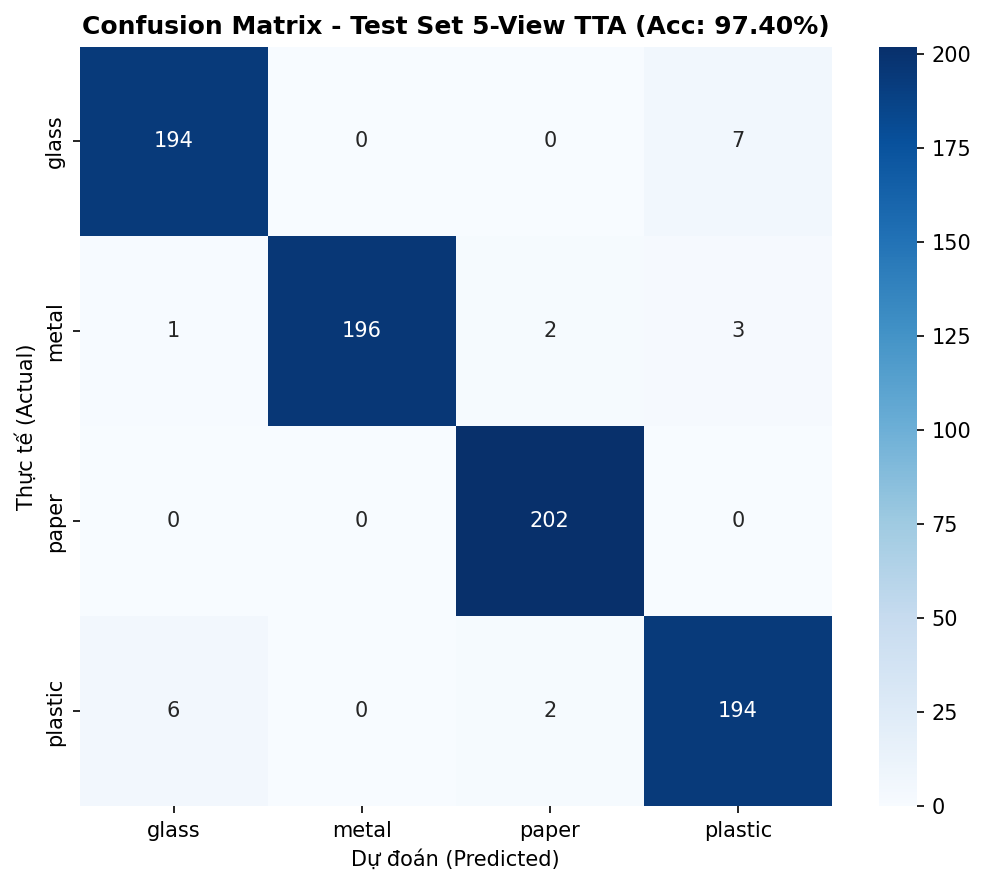


BÁO CÁO HỆ THỐNG AN TOÀN 5-VIEW TTA (KỸ THUẬT 1 & 2) TRÊN TẬP TEST:
Số mẫu tự động gắp an toàn           : 742 / 807 (91.95%)
ĐỘ CHÍNH XÁC KHI GẮP TỰ ĐỘNG         : 99.46% (738 / 742)
Số mẫu chuyển sang khay thủ công     : 65 / 807 (8.05%)
------------------------------------------------------------------------------------------
Tổng số lỗi sai thực tế trên tập Test: 21 mẫu (100.00%)
SỐ LỖI ĐÃ TÓM GỌN THÀNH CÔNG         : 17 / 21 (80.95%)
SỐ LỖI CÒN BỊ LỌT LƯỚI (CẢNH BÁO)    : 4 / 21 (19.05%)
✅ Đã lưu toàn bộ báo cáo vào file: 'safety_v2_classification_report.csv'.


In [7]:
# CELL 9 === 9. VẬN HÀNH BỘ LỌC 5-VIEW TTA + 2 CHỐT CHẶN TRÊN TẬP TEST & XUẤT BÁO CÁO NGHIỆM THU ===
print('=' * 95)
print('BƯỚC 2: SUY LUẬN 5-VIEW TTA & VẬN HÀNH HỆ THỐNG AN TOÀN TRÊN TẬP TEST ĐỘC LẬP...')
print('=' * 95)

test_filepaths = test_df['filepath'].values
test_trues = test_df['label'].map(sub_to_idx).values
test_filenames = test_df['filename'].values
N_test = len(test_filepaths)

# Dự đoán 5 góc nhìn TTA trên tập Test
test_views_probs = []
for v in range(5):
    print(f' -> Đang dự đoán View {v+1}/5 trên tập Test...')
    v_ds = make_tta_dataset(test_filepaths, view_idx=v, batch_size=BATCH_SIZE*2)
    logits = sub_logits_model.predict(v_ds, batch_size=BATCH_SIZE*2, verbose=0)
    probs = softmax(logits, axis=1)
    test_views_probs.append(probs)

# Tổng hợp kết quả 5-View TTA trên tập Test
test_tta_probs = np.mean(test_views_probs, axis=0)
test_final_preds = np.argmax(test_tta_probs, axis=1)

test_sorted_probs = np.sort(test_tta_probs, axis=1)
test_max_confs = test_sorted_probs[:, -1]
test_margins = test_sorted_probs[:, -1] - test_sorted_probs[:, -2]

# Tính độ đồng thuận giữa 5 góc nhìn TTA (để hiển thị thông tin bổ trợ trực quan)
test_views_preds = np.argmax(np.array(test_views_probs), axis=2)  # shape: (5, N_test)
test_tta_stability = np.mean(test_views_preds == test_final_preds[None, :], axis=0)

# Bảng phân loại tổng thể 5-View TTA trên Test (trước khi qua chốt chặn)
test_raw_acc = np.mean(test_final_preds == test_trues) * 100.0
total_errors = int(np.sum(test_final_preds != test_trues))
print(f'\n📊 Độ chính xác 5-View TTA gốc trên tập Test: {test_raw_acc:.2f}% ({total_errors} lỗi trên {N_test} mẫu)')
print('\n--- CLASSIFICATION REPORT (TEST SET - 5-VIEW TTA) ---')
print(classification_report(test_trues, test_final_preds, target_names=class_labels, digits=4))

# Vẽ Confusion Matrix trên tập Test
test_cm = confusion_matrix(test_trues, test_final_preds)
plt.figure(figsize=(7, 6), dpi=150)
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title(f'Confusion Matrix - Test Set 5-View TTA (Acc: {test_raw_acc:.2f}%)', fontweight='bold')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()
plt.savefig('confusion_matrix_test_tta.png', dpi=300)
plt.show()

# Duyệt từng mẫu qua 2 Chốt chặn An toàn (Kỹ thuật 1: Confidence Gate & Kỹ thuật 2: Margin Gate)
records_test = []
for i in range(N_test):
    pred_c = test_final_preds[i]
    true_c = test_trues[i]
    top1_c = float(test_max_confs[i])
    m_val = float(test_margins[i])
    tta_stab = float(test_tta_stability[i])

    # 👉 LẤY NGƯỠNG RIÊNG CỦA LỚP ĐƯỢC DỰ ĐOÁN:
    tau_conf_c = TAU_CONF_DICT[pred_c]

    pass_col1 = (top1_c >= tau_conf_c)
    pass_col2 = (m_val >= TAU_MARGIN)

    reasons = []
    if not pass_col1:
        reasons.append(f'Chốt 1 - Tự tin thấp lớp {class_labels[pred_c]} ({top1_c*100:.1f}% < {tau_conf_c*100:.1f}%)')
    if not pass_col2:
        reasons.append(f'Chốt 2 - Biên Margin hẹp ({m_val*100:.1f}% < {TAU_MARGIN*100:.1f}%)')

    if pass_col1 and pass_col2:
        decision = 'Tu_Dong_Gap'
        reason = 'Đạt chuẩn an toàn 5-View TTA (Vượt qua Chốt 1 & Chốt 2)'
    else:
        decision = 'Chuyen_Khay_Thu_Cong'
        reason = ' | '.join(reasons)

    records_test.append({
        'filename': test_filenames[i],
        'filepath': test_filepaths[i],
        'true_label': class_labels[true_c],
        'pred_label': class_labels[pred_c],
        'confidence': f'{top1_c*100:.2f}%',
        'margin': f'{m_val*100:.2f}%',
        'tta_stability': f'{tta_stab*100:.0f}%',
        'decision': decision,
        'reason': reason
    })

df_results = pd.DataFrame(records_test)

auto_samples = df_results[df_results['decision'] == 'Tu_Dong_Gap']
manual_samples = df_results[df_results['decision'] == 'Chuyen_Khay_Thu_Cong']

caught_errors = manual_samples[manual_samples['true_label'] != manual_samples['pred_label']]
leaked_errors = auto_samples[auto_samples['true_label'] != auto_samples['pred_label']]

auto_acc = np.mean(auto_samples['true_label'] == auto_samples['pred_label']) * 100.0 if len(auto_samples) > 0 else 0.0
caught_rate = (len(caught_errors) / total_errors * 100.0) if total_errors > 0 else 100.0
leaked_rate = (len(leaked_errors) / total_errors * 100.0) if total_errors > 0 else 0.0

# IN BÁO CÁO NGHIỆM THU THEO ĐÚNG FORM MẪU CỦA CELL 16
print('\n' + '=' * 90)
print('BÁO CÁO HỆ THỐNG AN TOÀN 5-VIEW TTA (KỸ THUẬT 1 & 2) TRÊN TẬP TEST:')
print('=' * 90)
print(f'Số mẫu tự động gắp an toàn           : {len(auto_samples)} / {N_test} ({len(auto_samples)/N_test*100:.2f}%)')
print(f'ĐỘ CHÍNH XÁC KHI GẮP TỰ ĐỘNG         : {auto_acc:.2f}% ({len(auto_samples) - len(leaked_errors)} / {len(auto_samples)})')
print(f'Số mẫu chuyển sang khay thủ công     : {len(manual_samples)} / {N_test} ({len(manual_samples)/N_test*100:.2f}%)')
print('-' * 90)
print(f'Tổng số lỗi sai thực tế trên tập Test: {total_errors} mẫu (100.00%)')
print(f'SỐ LỖI ĐÃ TÓM GỌN THÀNH CÔNG         : {len(caught_errors)} / {total_errors} ({caught_rate:.2f}%)')
print(f'SỐ LỖI CÒN BỊ LỌT LƯỚI (CẢNH BÁO)    : {len(leaked_errors)} / {total_errors} ({leaked_rate:.2f}%)')
print('=' * 90)

df_results.to_csv('safety_v2_classification_report.csv', index=False, encoding='utf-8-sig')
print("✅ Đã lưu toàn bộ báo cáo vào file: 'safety_v2_classification_report.csv'.")

In [ ]:
# CELL 10 === 10. TRỰC QUAN HÓA HÌNH ẢNH CÁC MẪU ĐOÁN ĐÚNG, LỖI ĐÃ CHẶN & LỖI LỌT LƯỚI ===
def plot_inspected_samples(samples_df, title, num_show=6, title_color='#d62728', save_name='samples_inspected.png'):
    if len(samples_df) == 0:
        print(f'ℹ️ Không có mẫu nào để hiển thị cho: {title}')
        return

    num_show = min(num_show, len(samples_df))
    cols = 3
    rows = int(np.ceil(num_show / cols))

    # Tăng kích thước chiều cao và chiều ngang để text không bị tràn cột
    fig, axes = plt.subplots(rows, cols, figsize=(16.5, 6.2 * rows), dpi=150)
    fig.suptitle(title, fontsize=13.5, fontweight='bold', y=0.98 if rows > 1 else 0.99)
    
    axes_flat = np.array(axes).reshape(-1)

    for idx in range(num_show):
        row = samples_df.iloc[idx]
        img_path = str(row['filepath'])
        img = None
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if img is None:
            img = np.zeros((IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.uint8)

        ax = axes_flat[idx]
        ax.imshow(img)
        ax.axis('off')

        # Rút gọn tên file nếu quá dài
        fname = os.path.basename(str(row['filename']))
        if len(fname) > 26:
            fname = fname[:23] + '...'

        # 👉 XUỐNG DÒNG GIỮA CHỐT 1 VÀ CHỐT 2 ĐỂ KHÔNG BỊ TRÀN NGANG SANG CỘT BÊN CẠNH
        reason_formatted = str(row['reason']).replace(' | ', '\n')

        caption = (
            f"File: {fname}\n"
            f"Thực tế: {row['true_label'].upper()}  |  Dự đoán: {row['pred_label'].upper()} (Conf: {row['confidence']})\n"
            f"Biên: {row['margin']}  |  Đồng thuận TTA: {row['tta_stability']}\n"
            f"{reason_formatted}"
        )
        
        # Cỡ chữ 8.2pt và linespacing=1.2 giúp các dòng text hiển thị rất sắc nét, gọn gàng
        ax.set_title(caption, fontsize=8.2, color=title_color, fontweight='bold', pad=7, linespacing=1.2)

    # Ẩn các ô trống nếu số ảnh không đủ 3 cột
    for j in range(num_show, len(axes_flat)):
        axes_flat[j].axis('off')

    # wspace=0.35 tạo khoảng cách thoáng giữa các cột, hspace=0.56 tạo khoảng cách giữa các hàng
    plt.subplots_adjust(top=0.91 if rows > 1 else 0.83, bottom=0.06, hspace=0.56, wspace=0.35)
    plt.savefig(save_name, dpi=300, bbox_inches='tight')
    plt.show()

# Tách nhóm các mẫu Chuyển khay thủ công: Đoán SAI (Cứu nguy) vs Đoán ĐÚNG (Thận trọng)
manual_wrong = manual_samples[manual_samples['true_label'] != manual_samples['pred_label']]
manual_correct = manual_samples[manual_samples['true_label'] == manual_samples['pred_label']]

print('=' * 90)
print(f"📊 THỐNG KÊ KHAY THỦ CÔNG: Tổng {len(manual_samples)} mẫu = {len(manual_wrong)} mẫu sai (cứu nguy) + {len(manual_correct)} mẫu đúng (thận trọng)")
print('=' * 90)

# 1. HIỂN THỊ 6 MẪU CHUYỂN THỦ CÔNG DO ĐOÁN SAI (LỖI ĐÃ TÓM GỌN THÀNH CÔNG VÀO KHAY)
if len(manual_wrong) > 0:
    plot_inspected_samples(
        manual_wrong.head(6),
        title=f'CÁC MẪU LỖI SAI ĐƯỢC CHẶN VÀO KHAY THỦ CÔNG (HIỂN THỊ 6/{len(manual_wrong)} LỖI)',
        num_show=6,
        title_color='#d62728',
        save_name='mau_sai_chuyen_thu_cong_convnext_tta.png'
    )

# 2. HIỂN THỊ 6 MẪU CHUYỂN THỦ CÔNG DÙ ĐOÁN ĐÚNG (CẢNH BÁO AN TOÀN DO CHƯA ĐẠT CHUẨN)
if len(manual_correct) > 0:
    plot_inspected_samples(
        manual_correct.sample(min(6, len(manual_correct)), random_state=SEED),
        title=f'CÁC MẪU ĐOÁN ĐÚNG NHƯNG CHUYỂN THỦ CÔNG CẨN TRỌNG (HIỂN THỊ 6/{len(manual_correct)} MẪU)',
        num_show=6,
        title_color='#1f77b4',
        save_name='mau_dung_chuyen_thu_cong_convnext_tta.png'
    )

# 3. HIỂN THỊ CÁC MẪU LỖI CÒN BỊ LỌT LƯỚI (NẾU CÓ)
if len(leaked_errors) > 0:
    plot_inspected_samples(
        leaked_errors,
        title=f'CẢNH BÁO: CÁC MẪU LỖI CÒN BỊ LỌT LƯỚI ({len(leaked_errors)}/{total_errors} LỖI)',
        num_show=min(6, len(leaked_errors)),
        title_color='#ff7f0e',
        save_name='mau_sai_lot_luoi_convnext_tta.png'
    )
else:
    print('🎉 Tuyệt vời! Không có mẫu lỗi nào bị lọt lưới (0 lỗi lọt lưới).')

# 4. HIỂN THỊ 6 MẪU DỰ ĐOÁN ĐÚNG & GẮP TỰ ĐỘNG AN TOÀN TIÊU BIỂU
correct_auto_samples = auto_samples[auto_samples['true_label'] == auto_samples['pred_label']]
if len(correct_auto_samples) > 0:
    plot_inspected_samples(
        correct_auto_samples.sample(min(6, len(correct_auto_samples)), random_state=SEED),
        title='CÁC MẪU DỰ ĐOÁN ĐÚNG & TỰ ĐỘNG GẮP AN TOÀN TIÊU BIỂU (6 MẪU)',
        num_show=6,
        title_color='#2ca02c',
        save_name='mau_dung_tu_dong_gap_convnext_tta.png'
    )